In [1]:
# gini impurity
# entropy gain
# entropy is a key metric from information theory used to measure the impurity or uncertainty in a dataset.
# why even find entropy?? to get Information gain in order to get the root of DT
from sklearn.tree import DecisionTreeClassifier,plot_tree,export_text

In [ ]:
# entropy=0 when data is pure
# entropy=1 when equal bifurcation

In [2]:
import pandas as pd

In [3]:
df=pd.DataFrame({'Job':[1,1,0,1,0,0,1,0],
                'Savings':[1,0,0,0,1,1,0,0],
                'Buy_Car':[1,0,1,1,1,1,0,0]})

In [4]:
x=df.drop(columns='Buy_Car')
y=df['Buy_Car']

In [5]:
from sklearn.tree import DecisionTreeClassifier,plot_tree,export_text

In [6]:
dt=DecisionTreeClassifier(criterion='entropy') #gini is default
dt.fit(x,y)

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [9]:
tree_text=export_text(dt)
print(tree_text) #root node is saving(index=1)

|--- feature_1 <= 0.50
|   |--- feature_0 <= 0.50
|   |   |--- class: 0
|   |--- feature_0 >  0.50
|   |   |--- class: 0
|--- feature_1 >  0.50
|   |--- class: 1



In [11]:
tree_text=export_text(dt,feature_names=['Job','Savings'])
print(tree_text)

|--- savings <= 0.50
|   |--- Job <= 0.50
|   |   |--- class: 0
|   |--- Job >  0.50
|   |   |--- class: 0
|--- savings >  0.50
|   |--- class: 1



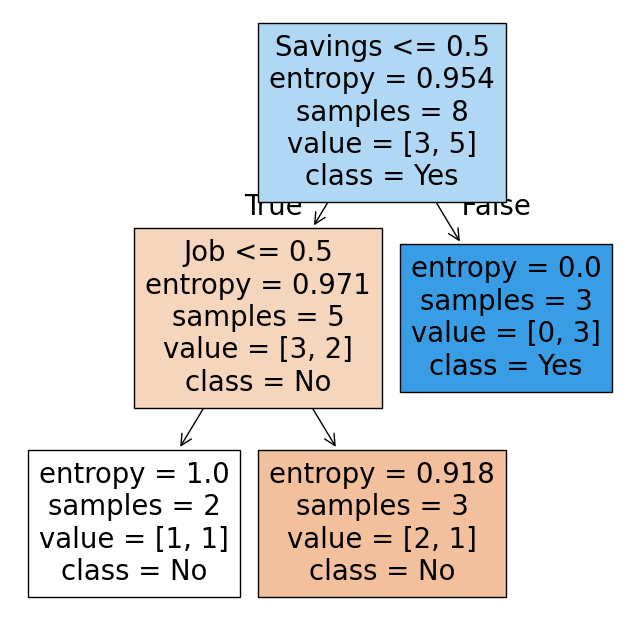

In [19]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(8,8))
plot_tree(dt,feature_names=['Job','Savings'],class_names=['No','Yes'],filled=True)
plt.show() 
# orangish,colorless=>unsolvable mixed impurities

In [24]:
df=pd.read_csv('Decision Tree.csv')
df

,CGPA,Communication,Aptitute,Programming Skills,Job Offered?
0,1,1,1,1,1
1,2,1,1,1,1
2,0,0,0,1,0
3,0,1,0,0,0
4,1,1,1,0,1
5,1,1,1,1,1
6,2,0,0,0,0
7,2,0,0,1,0
8,1,0,1,1,1
9,2,1,1,1,1


In [25]:
df.duplicated().sum()# doesn't matter here

np.int64(5)

In [26]:
y=df['Job Offered?']
x=df.drop(columns='Job Offered?')

In [29]:
from sklearn.tree import DecisionTreeClassifier,plot_tree,export_text
dt=DecisionTreeClassifier(criterion='entropy')
dt.fit(x,y)

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [32]:
text=export_text(dt,feature_names=['CGPA','Communication','Aptitude','Programming Skills'])
print(text)

|--- Aptitude <= 0.50
|   |--- class: 0
|--- Aptitude >  0.50
|   |--- Communication <= 0.50
|   |   |--- Programming Skills <= 0.50
|   |   |   |--- class: 0
|   |   |--- Programming Skills >  0.50
|   |   |   |--- CGPA <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- CGPA >  1.50
|   |   |   |   |--- class: 0
|   |--- Communication >  0.50
|   |   |--- class: 1



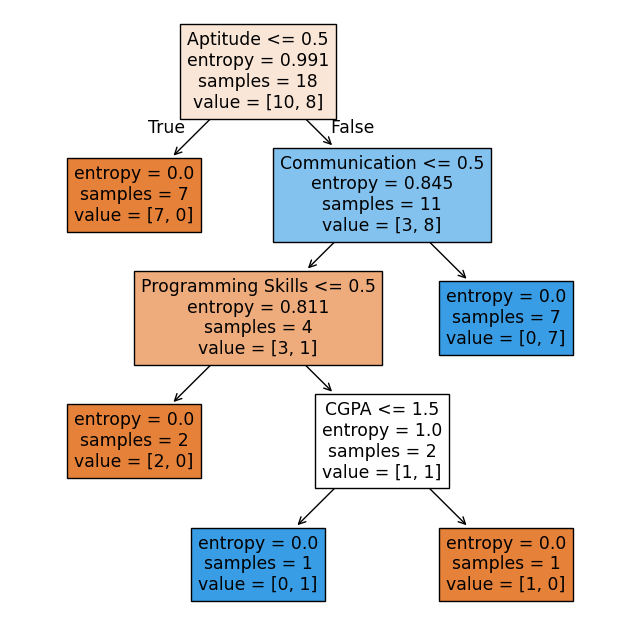

In [34]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(8,8))
plot_tree(dt,feature_names=['CGPA','Communication','Aptitude','Programming Skills'],class_names=['No','Yes'],filled=True)
plt.show() 


In [35]:
y_pred=dt.predict(x)

In [38]:
from sklearn.metrics import accuracy_score,recall_score,confusion_matrix,classification_report
print('Accuracy_Score:',accuracy_score(y,y_pred)) # accuracy comes out to be 1 =>The model is overfitted
print('Recall_Score:',recall_score(y,y_pred))
print("----Confusion matrix----")
print(confusion_matrix(y,y_pred))
print("----Classification Report----")
print(classification_report(y,y_pred))

Accuracy_Score: 1.0
Recall_Score: 1.0
----Confusion matrix----
[[10  0]
 [ 0  8]]
----Classification Report----
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         8

    accuracy                           1.00        18
   macro avg       1.00      1.00      1.00        18
weighted avg       1.00      1.00      1.00        18



In [48]:
print(dt.predict([[2,1,1,1]]))

[1]


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [49]:
df=pd.read_csv('PlayTennis.csv')
df

,outlook,temp,humidity,windy,play
0,sunny,hot,high,False,no
1,sunny,hot,high,True,no
2,overcast,hot,high,False,yes
3,rainy,mild,high,False,yes
4,rainy,cool,normal,False,yes
5,rainy,cool,normal,True,no
6,overcast,cool,normal,True,yes
7,sunny,mild,high,False,no
8,sunny,cool,normal,False,yes
9,rainy,mild,normal,False,yes


In [42]:
import numpy as np
df['outlook']=df['outlook'].replace({'sunny':0,'overcast':1,'rainy':2})
df['temp']=df['temp'].replace({'hot':0,'mild':1,'cool':2})
df['humidity']=df['humidity'].replace({'normal':0,'high':1})
df['windy']=df['windy'].replace({False:0,True:1}) # check using .info() bool OR object
df['play']=df['play'].replace({'no':0,'yes':1})

C:\Users\LJENG\AppData\Local\Temp\ipykernel_11128\2862972876.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['humidity']=df['humidity'].replace({'normal':0,'high':1})
C:\Users\LJENG\AppData\Local\Temp\ipykernel_11128\2862972876.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['windy']=df['windy'].replace({False:0,True:1}) # check using .info() bool OR object
C:\Users\LJENG\AppData\Local\Temp\ipykernel_11128\2862972876.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future 

In [43]:
df

,outlook,temp,humidity,windy,play
0,0,0,1,0,0
1,0,0,1,1,0
2,1,0,1,0,1
3,2,1,1,0,1
4,2,2,0,0,1
5,2,2,0,1,0
6,1,2,0,1,1
7,0,1,1,0,0
8,0,2,0,0,1
9,2,1,0,0,1


In [51]:
dt=DecisionTreeClassifier(criterion='entropy')
dt
x=df.drop(columns='play')
y=df['play']
dt.fit(x,y)

y_pred=dt.predict(x)
print('Accuracy_score:',accuracy_score(y,y_pred))

ValueError: could not convert string to float: 'sunny'